In [1]:
from astropy.wcs import WCS
from astropy.io import fits
from astropy.utils.data import get_pkg_data_filename
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize, CenteredNorm
import numpy as np

from astropy import units as u
from astropy.coordinates import SkyCoord


from astropy.stats import sigma_clipped_stats
from photutils.detection import DAOStarFinder


/home/brad/miniforge3/envs/diss/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
hdu = fits.open("data/pn-all.fits")[0]
wcs = WCS(hdu.header)

the RADECSYS keyword is deprecated, use RADESYSa. [astropy.wcs.wcs]
Set MJD-OBS to 56323.504653 from DATE-OBS.
Set MJD-END to 56325.052986 from DATE-END'. [astropy.wcs.wcs]


Centre = 25599.474052059446, 23866.25599110693


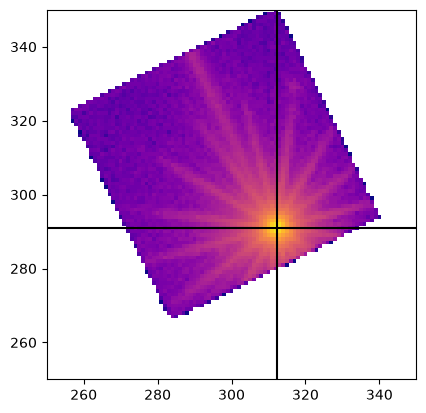

In [3]:
fig, ax = plt.subplots()
data = hdu.data

ax.imshow(data, origin='lower', norm=LogNorm(), cmap="plasma")
ax.set_xlim(250, 350)
ax.set_ylim(250, 350)

data = hdu.data[0:400, 0:400]
mean, median, std = sigma_clipped_stats(data, sigma=3.0)
daofind = DAOStarFinder(fwhm=3.0, threshold=1*std)    
sources = daofind(data - median)    

idx = sources[sources["mag"] == sources["mag"].min()]["id"]-1
factor = hdu.header["CDELT1L"]
print(f"Centre = {factor*sources[idx]["x_centroid"].data[0]}, {factor*sources[idx]["y_centroid"].data[0]}")

ax.vlines([sources[idx]["x_centroid"]], ymin=250, ymax=350, color="black")
ax.hlines([sources[idx]["y_centroid"]], xmin=250, xmax=350, color="black")